In [1]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [2]:
from datetime import datetime
import functools
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm

import matplotlib.pyplot as plt

In [3]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Load gatesets

## 1 QB

In [4]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
knames = ["X1", "X2", "SX1", "SX2"]
pico_a = {k: v for k, v in zip(knames, ps.from_csv(fname))}

# The initial run takes awhile to construct the symbolic pulse shapes
x_gates = {}
for k, v in pico_a.items():
    x_gates[k] = ps.scalable_symbolic_pulse(duration_1qb, v, f"custom-{k}")

# Calibrate the X gates
cal_x_gates = {}
cal_values = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi]
for θ, (k, v) in zip(cal_values, x_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )

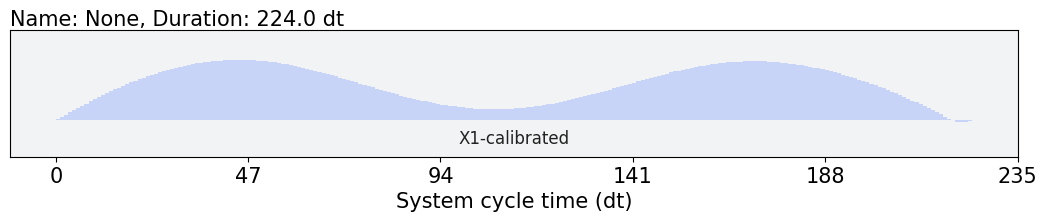

In [5]:
cal_x_gates['X1'].draw()

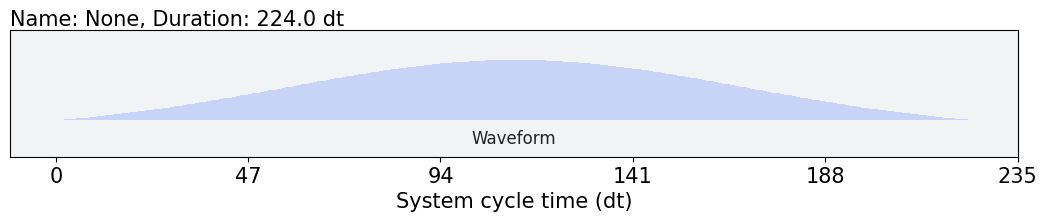

In [6]:
default_gates = {}
for k in pico_a.keys():
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 4)
    else:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)

default_gates["X1"].draw()

In [7]:
np.trapz(ps.get_samples(default_gates['SX1']), dx=dt) / np.pi, np.trapz(ps.get_samples(default_gates['SX2']), dx=dt) / np.pi, 

((0.2499980513253951+0j), (0.2499980513253951+0j))

In [8]:
np.trapz(ps.get_samples(default_gates['X1']), dx=dt) / np.pi, np.trapz(ps.get_samples(default_gates['X2']), dx=dt) / np.pi, 

((0.4999961026507902+0j), (0.4999961026507902+0j))

## 2 qb

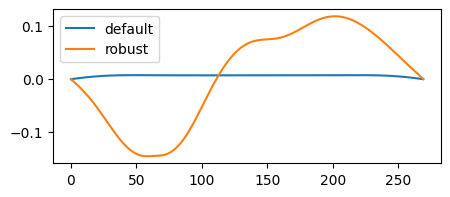

In [9]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"
knames = ["default", "robust"]
pico2_a = {k: ps.from_csv(fname(k))[0] for k in knames}

# Less precise about optimization than before...
fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico2_a.items():
    ax.plot(v, label=k)
ax.legend()

# Downsample the pulse to make construction faster
cr_gates = {}
for k, v in pico2_a.items():
    cr_gates[k] = ps.scalable_symbolic_pulse(
        duration_2qb,
        ps.resample(51, v, keep_step=False),
        f"cr-{k}"
    )

# Add positive and negative rotations to gateset
cal_cr_gates = {}
cal_values = [0.125 * np.pi, 0.125 * np.pi]
for θ, (k, v) in zip(cal_values, cr_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_cr_gates[k] = {
        "+": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated+amp",
            duration=duration_2qb,
            amp=amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
        "-": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated-amp",
            duration=duration_2qb,
            amp=-amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
    }

# Model

TODO: We should have a check in case you try to play a pulse on a channel that does not have a model.

In [10]:
registers = [0, 1, 2, 3]

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        cvars[k] = 250 / μs * ns
    if "t2" in k:
        cvars[k] = 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

H_cr = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    model_name="Toy",
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

H_xtalk = ps.crosstalk_model(registers, ps.backend_edges(backend), cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

    # Two qubit with ring connectivity
    if qubit < len(registers) - 1:
        control, target = qubit, qubit + 1
        
        # Get both directions
        for pair in [(control, target), (target, control)]:
            Hj_drift, Hjs_control, Hjs_channel = H_cr(pair)
            H_drift += Hj_drift
            Hs_control += Hjs_control
            Hs_channels += Hjs_channel

# Some models may repeat control channels
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# NOTE: We won't use carriers in this example
# =====
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

# registered_carriers = {c: carriers[c] for c in Hs_channels}
# cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

# Solver

In [11]:
# Models already in the rotating frame
# NOTE: Can't phase shift controls without carriers
# =====
solver_r = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_r0 = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

# Convert circuit to schedule

![The Hamiltonain simulation](./../figures/hamiltonian-simulation-circuit.png)

Y gates require applying Z gates using separate Hamiltonians and fictituous drive lines. We use singl time step Z gates.

In [12]:
my_moments = [
    {0: np.pi / 2, 2: np.pi / 2},
    {0: "SX2", 1: "SX1", 2:"SX2", 3: "SX1"},
    {1: np.pi / 2, 3: np.pi / 2},
    {(0, 1): "X2", (2, 3): "X2"},
    {0: np.pi / 2, 1: -np.pi, 2: np.pi / 2, 3: -np.pi},
    {0: "SX2", 1: "SX1", 2:"SX2", 3: "SX1"},
    {0: np.pi / 10, 1: -np.pi, 2: np.pi / 10, 3: -np.pi},
    {0: "SX2", 2:"SX2"},
    {(0, 1): "X2", (2, 3): "X2"},
    {0: "X2", 2:"SX2"},
    {0: np.pi / 10, 1: -np.pi/2, 3: np.pi / 10},
    {(1, 2): "X1"},
    {1: np.pi / 2, 2: -np.pi},
    {1: "SX1", 2: "SX2"},
    {1: np.pi / 10, 2: -np.pi},
    {1: "SX1"},
    {(1, 2): "X1"},
    {1: "X1"},
    {1: np.pi / 10, 2: np.pi / 10},
]

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


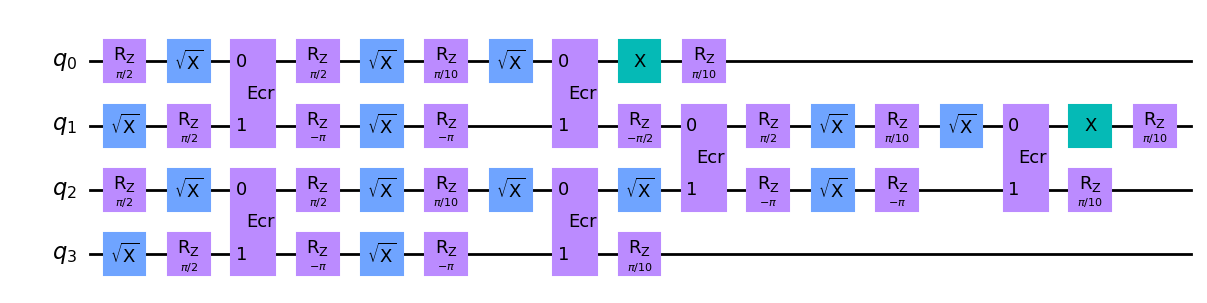

In [13]:
circ = ps.build_circuit(my_moments, registers)
circ.draw('mpl')

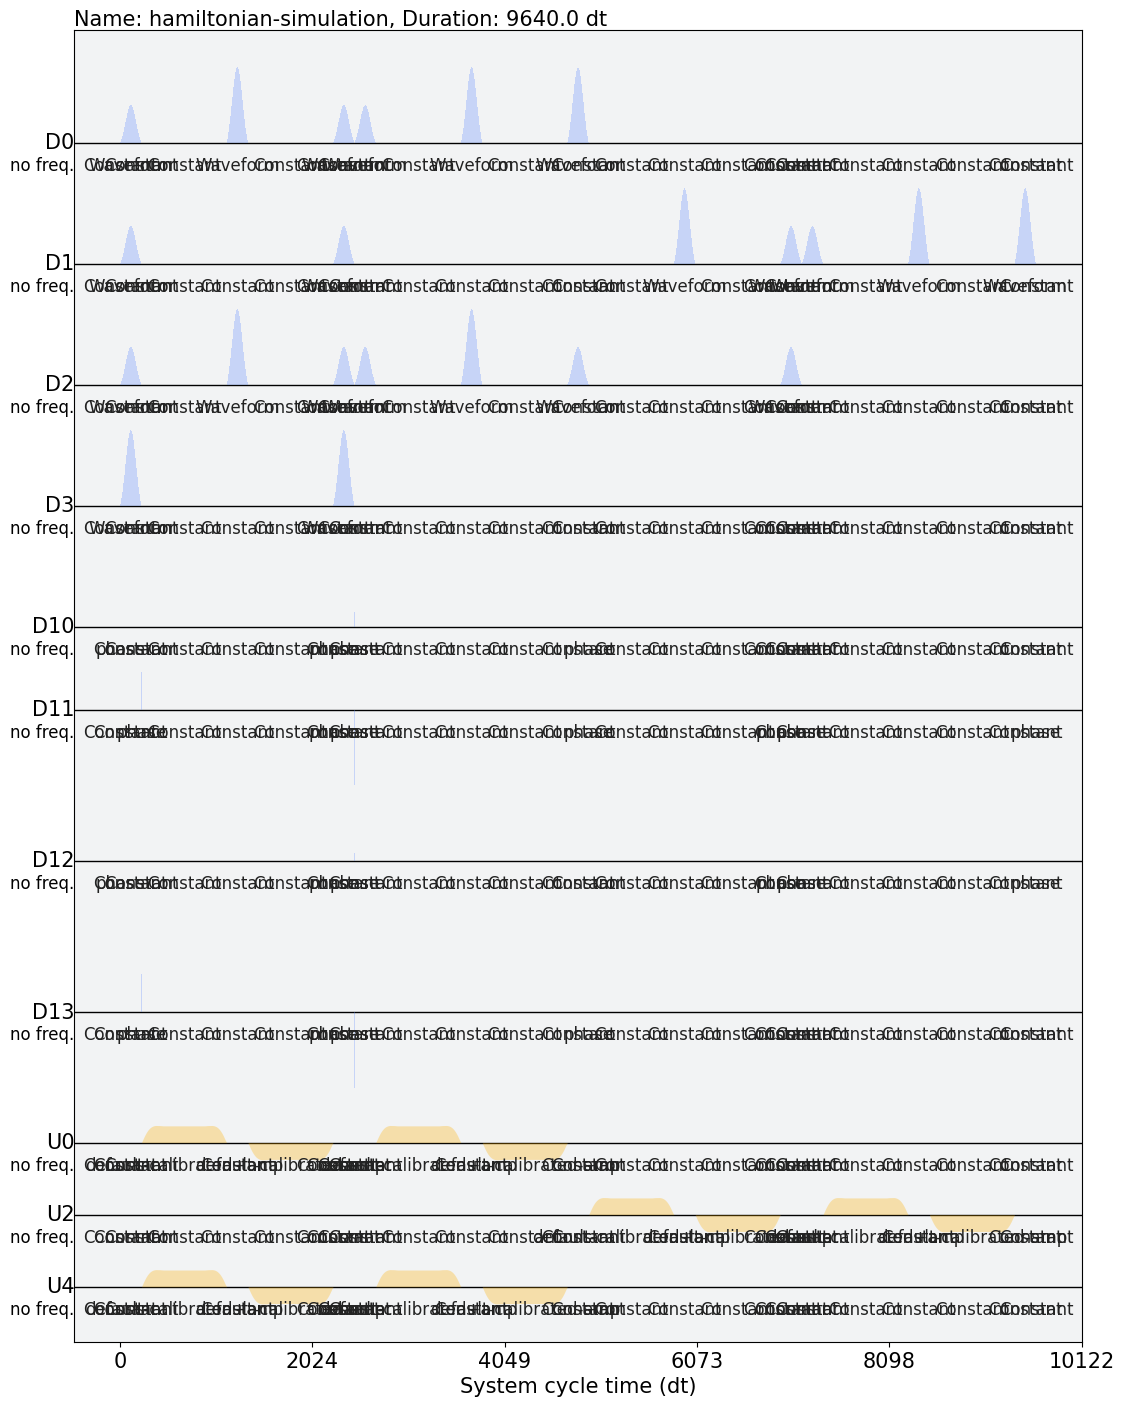

In [14]:
sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['default'],
    # qubit_gates=cal_x_gates,
    # cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

# Would be nice to disable phase channels
sched.draw()

# Simulate schedule with solver

Seems like there is trouble with the endians.

In [15]:
y0 = ps.qiskit_identity_operator(len(registers))

solver_r0.model.evaluation_mode = 'sparse'
res = solver_r0.solve(
    t_span=[0., sched.duration], 
    t_eval=[sched.duration], 
    y0=y0, 
    signals=sched,
    atol=1e-12,
    rtol=1e-12,
    method='jax_odeint'
)

In [16]:
# Compute fidelity
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
qk.quantum_info.process_fidelity(res.y[-1], target)

0.999999826310688

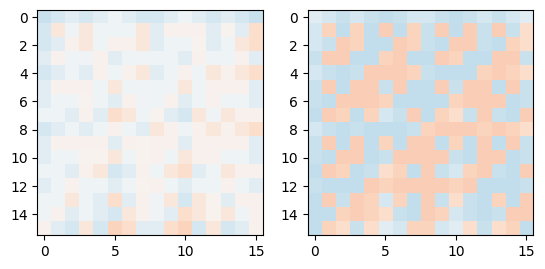

In [17]:
fig, axes = plt.subplots(1, 2)
scale = 1
axes[0].imshow(res.y[-1].data.real, cmap='RdBu', vmin=-scale, vmax=scale)
axes[1].imshow(res.y[-1].data.imag, cmap='RdBu', vmin=-scale, vmax=scale)

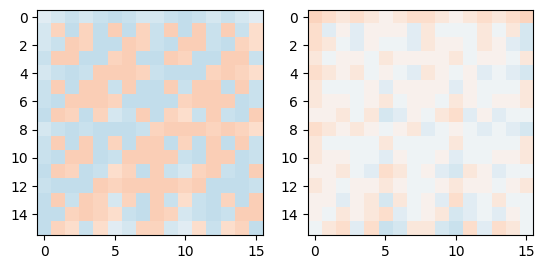

In [18]:
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

fig, axes = plt.subplots(1, 2)
scale = 1
axes[0].imshow(target.data.real, cmap='RdBu', vmin=-scale, vmax=scale)
axes[1].imshow(target.data.imag, cmap='RdBu', vmin=-scale, vmax=scale)

### Note phase on $\sqrt{X}$

In [19]:
x = np.array([[0, 1], [1, 0]])
sx = np.exp(-1j * np.pi / 4) * sqrtm(x)
i = np.eye(2)

A = expm(-1j * np.pi / 4 * np.kron(np.kron(i, i), x)) @ expm(
    -1j * np.pi / 4 * np.kron(np.kron(i, x), i)
) @ expm(-1j * np.pi / 4 * np.kron(np.kron(x, i), i))

B = np.kron(np.kron(i, i), sx) @ np.kron(np.kron(i, sx), i) @ np.kron(np.kron(sx, i), i)

# Phase is required for the elements to match
np.all(np.isclose(A, B))


True